# 03 · Caracterização e descoberta de regimes (E1)
**CRISP-DM:** Entendimento dos Dados + Modelagem descritiva · **RQ1**

Objetivo: confirmar empiricamente que **cada recurso tem vários comportamentos normais ligados ao contexto** e nomeá-los.

1. Perfis por hora × tipo de dia e mapa de calor (treino: agosto);
2. Testes: **Kruskal-Wallis** entre as 24 horas (dias úteis) e **Mann-Whitney** útil × sábado e sábado × domingo, com correção de **Holm**;
3. **k-means** só com atributos de comportamento, k por silhouette; qualidade (silhouette, Davies-Bouldin, Calinski-Harabasz), estabilidade entre quinzenas (ARI) e associação regime × contexto (V de Cramér);
4. Nomeação dos regimes pelo cruzamento com o contexto.

In [1]:
%run ./00_funcoes.ipynb

00_funcoes carregado · raiz: /home/wsl/gh/mestrado/claude9


In [2]:
jan = pd.read_parquet(RESULTADOS / f"02_janelas_{JANELA}.parquet")
tr = recortar(jan, TREINO)
recursos = sorted(tr["recurso"].unique())
REPRESENTATIVOS = [18169917, 18166630, 14553746, 18917906]

## 1. Perfis por hora e tipo de dia

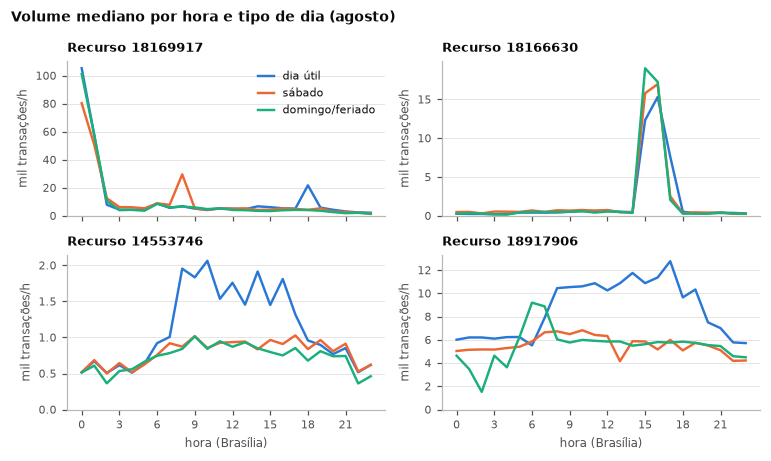

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(7.0, 4.2), sharex=True)
for ax, r in zip(axes.flat, REPRESENTATIVOS):
    g = tr[tr["recurso"] == r].groupby(["tipo_dia", "hora"])["vol"].median().unstack(0) / 1000
    for td in ["util", "sabado", "domingo_feriado"]:
        ax.plot(g.index, g[td], color=COR_DIA[td], lw=1.6, label=NOMES_DIA[td])
    ax.set_title(f"Recurso {r}", loc="left")
    ax.set_xticks(range(0, 24, 3))
    ax.set_ylim(bottom=0)
    ax.set_ylabel("mil transações/h")
    ax.grid(axis="x", visible=False)
for ax in axes[1]:
    ax.set_xlabel("hora (Brasília)")
axes[0, 0].legend(loc="upper right", ncol=1, handlelength=1.5)
fig.suptitle("Volume mediano por hora e tipo de dia (agosto)", x=0.01, ha="left", fontsize=9, fontweight="bold")
fig.tight_layout()
salvar(fig, "fig_perfis_volume")
plt.show()

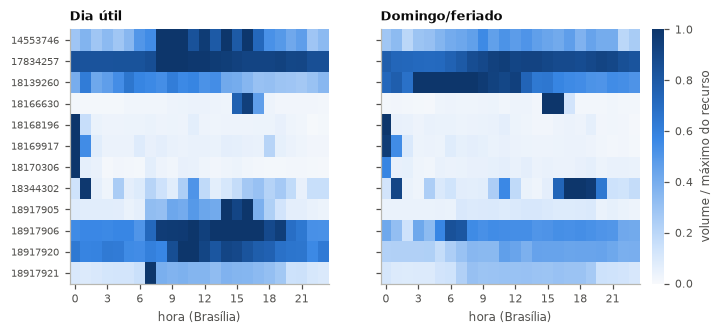

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.0), sharey=True)
for ax, td in zip(axes, ["util", "domingo_feriado"]):
    m = tr[tr["tipo_dia"] == td].groupby(["recurso", "hora"])["vol"].median().unstack()
    m = m.div(tr.groupby(["recurso", "hora"])["vol"].median().unstack().max(axis=1), axis=0)
    im = ax.imshow(m.to_numpy(), aspect="auto", cmap=CMAP_SEQ, vmin=0, vmax=1)
    ax.set_title(f"{NOMES_DIA[td].capitalize()}", loc="left")
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlabel("hora (Brasília)")
    ax.set_yticks(range(len(m)))
    ax.set_yticklabels(m.index, fontsize=6.5)
    ax.grid(False)
cb = fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02)
cb.set_label("volume / máximo do recurso", color=TXT2)
cb.outline.set_visible(False)
salvar(fig, "fig_mapa_calor_volume")
plt.show()

## 2. Testes estatísticos
- **Kruskal-Wallis** (dias úteis): a distribuição de cada atributo difere entre as 24 horas? Tamanho de efeito ε² = (H − k + 1)/(n − k).
- **Mann-Whitney**: útil × sábado e sábado × domingo (todas as horas). Tamanho de efeito: correlação bisserial de postos r = 1 − 2U/(n₁n₂).
- Correção de **Holm** por família de testes; α = 0,05.

In [5]:
def holm(p):
    p = np.asarray(p, float)
    ordem = np.argsort(p)
    m = len(p)
    aj = np.empty(m)
    acum = 0
    for i, idx in enumerate(ordem):
        acum = max(acum, (m - i) * p[idx])
        aj[idx] = min(acum, 1.0)
    return aj


kw, mw = [], []
for r in recursos:
    g = tr[tr["recurso"] == r]
    u = g[g["tipo_dia"] == "util"]
    for a in ATRIBUTOS:
        grupos = [v[a].dropna().to_numpy() for _, v in u.groupby("hora")]
        if np.ptp(np.concatenate(grupos)) == 0:
            continue
        H, p = stats.kruskal(*grupos)
        n, k = sum(map(len, grupos)), len(grupos)
        kw.append(dict(recurso=r, atributo=a, H=H, p=p, eps2=(H - k + 1) / (n - k)))
        for a_, b_ in [("util", "sabado"), ("sabado", "domingo_feriado")]:
            x = g.loc[g["tipo_dia"] == a_, a].dropna()
            y = g.loc[g["tipo_dia"] == b_, a].dropna()
            if np.ptp(np.r_[x, y]) == 0:
                continue
            U, p2 = stats.mannwhitneyu(x, y, alternative="two-sided")
            mw.append(dict(recurso=r, atributo=a, par=f"{a_}×{b_}", p=p2, r_bisserial=1 - 2 * U / (len(x) * len(y))))
kw, mw = pd.DataFrame(kw), pd.DataFrame(mw)
kw["p_holm"] = holm(kw["p"])
mw["p_holm"] = mw.groupby("par")["p"].transform(holm)
kw["sig"], mw["sig"] = kw["p_holm"] < 0.05, mw["p_holm"] < 0.05

resumo_testes = pd.DataFrame({
    "KW horas: atributos sig.": kw.groupby("recurso")["sig"].sum(),
    "KW ε² volume": kw[kw["atributo"] == "log_vol"].set_index("recurso")["eps2"],
    "útil×sáb: atributos sig.": mw[mw["par"] == "util×sabado"].groupby("recurso")["sig"].sum(),
    "sáb×dom: atributos sig.": mw[mw["par"] == "sabado×domingo_feriado"].groupby("recurso")["sig"].sum(),
    "útil×sáb volume sig.": mw[(mw["par"] == "util×sabado") & (mw["atributo"] == "log_vol")].set_index("recurso")["sig"],
    "sáb×dom volume sig.": mw[(mw["par"] == "sabado×domingo_feriado") & (mw["atributo"] == "log_vol")].set_index("recurso")["sig"],
}).fillna(0)
resumo_testes

/tmp/ipykernel_226410/2709198004.py:21: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  H, p = stats.kruskal(*grupos)


,KW horas: atributos sig.,KW ε² volume,útil×sáb: atributos sig.,sáb×dom: atributos sig.,útil×sáb volume sig.,sáb×dom volume sig.
recurso,,,,,,
14553746,8,0.829357,3,0,True,False
17834257,2,-0.003558,1,0,False,False
18139260,7,0.077597,4,2,True,True
18166630,8,0.395123,2,4,False,True
18168196,8,0.384991,1,1,False,False
18169917,8,0.544427,1,1,False,False
18170306,8,0.233807,2,3,True,True
18344302,6,0.339302,1,0,False,False
18917905,8,0.661438,5,1,True,False


In [6]:
tot_kw = kw["sig"].mean()
sab_dom_vol = mw[(mw["par"] == "sabado×domingo_feriado") & (mw["atributo"] == "log_vol")]["sig"]
util_sab_vol = mw[(mw["par"] == "util×sabado") & (mw["atributo"] == "log_vol")]["sig"]
print(f"Kruskal-Wallis: {tot_kw:.0%} dos testes recurso × atributo significativos entre horas")
print(f"Volume útil × sábado significativo em {util_sab_vol.sum()}/{len(util_sab_vol)} recursos")
print(f"Volume sábado × domingo significativo em {sab_dom_vol.sum()}/{len(sab_dom_vol)} recursos")
# Decisão por recurso (prevista no plano): 3 categorias só onde o volume de sábado ≠ domingo
RECURSOS_3 = sorted(int(r) for r in mw[(mw["par"] == "sabado×domingo_feriado") & (mw["atributo"] == "log_vol") & mw["sig"]]["recurso"])
print("Recursos com 3 tipos de dia (útil / sábado / domingo-feriado):", RECURSOS_3)
print("Demais recursos: útil / não útil (feriado junto)")

Kruskal-Wallis: 85% dos testes recurso × atributo significativos entre horas
Volume útil × sábado significativo em 6/12 recursos
Volume sábado × domingo significativo em 4/12 recursos
Recursos com 3 tipos de dia (útil / sábado / domingo-feriado): [18139260, 18166630, 18170306, 18917920]
Demais recursos: útil / não útil (feriado junto)


## 3. Regimes por k-means (atributos de comportamento)
Por recurso: padronização, k de 2 a 8 escolhido pelo silhouette. Estabilidade: o k-means é ajustado separadamente em cada quinzena de agosto (mesmo k) e as duas partições de todas as janelas de agosto são comparadas pelo ARI. Associação com o contexto: V de Cramér entre regime e hora, e entre regime e tipo de dia.

In [7]:
def cramer_v(a, b):
    tab = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(tab, correction=False)[0]
    n = tab.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(tab.shape) - 1)))


Q1 = (pd.Timestamp("2026-08-01"), pd.Timestamp("2026-08-16"))
linhas, slots, nomes_todos, curvas = [], [], {}, {}
rotulos = {}
for r in recursos:
    g = tr[tr["recurso"] == r].reset_index(drop=True)
    esc = StandardScaler().fit(matriz_regimes(g))
    x = esc.transform(matriz_regimes(g))
    km, curva = kmeans_por_silhouette(x)
    curvas[r] = curva
    rot = km.labels_
    rotulos[r] = rot
    k = km.n_clusters
    q1 = (g["janela"] < Q1[1]).to_numpy()
    km1 = KMeans(n_clusters=k, n_init=10, random_state=0).fit(x[q1])
    km2 = KMeans(n_clusters=k, n_init=10, random_state=0).fit(x[~q1])
    nomes = nomear_regimes(g, rot)
    nomes_todos[r] = nomes
    linhas.append(dict(recurso=r, k=k, silhouette=silhouette_score(x, rot), davies_bouldin=davies_bouldin_score(x, rot),
                       calinski_harabasz=calinski_harabasz_score(x, rot),
                       ari_quinzenas=adjusted_rand_score(km1.predict(x), km2.predict(x)),
                       v_cramer_hora=cramer_v(rot, g["hora"]), v_cramer_tipo_dia=cramer_v(rot, g["tipo_dia"])))
    dom = g.assign(regime=rot).groupby(["tipo_dia", "hora"])["regime"].agg(
        lambda s: s.value_counts().index[0]).rename("regime").reset_index()
    freq = g.assign(regime=rot).groupby(["tipo_dia", "hora"])["regime"].agg(lambda s: s.value_counts(normalize=True).iloc[0])
    dom["freq"] = freq.to_numpy()
    dom["nome"] = dom["regime"].map(nomes)
    dom.insert(0, "recurso", r)
    slots.append(dom)

regimes = pd.DataFrame(linhas).set_index("recurso")
slots = pd.concat(slots, ignore_index=True)
regimes.round(3)

,k,silhouette,davies_bouldin,calinski_harabasz,ari_quinzenas,v_cramer_hora,v_cramer_tipo_dia
recurso,,,,,,,
14553746,3,0.306,1.100,208.873,0.801,0.472,0.315
17834257,2,0.853,0.530,345.199,-0.011,0.156,0.125
18139260,6,0.253,1.178,174.080,0.424,0.417,0.363
18166630,2,0.399,1.394,167.273,0.003,0.715,0.094
18168196,2,0.510,1.427,139.688,0.009,0.474,0.048
18169917,2,0.293,1.673,137.483,0.007,0.676,0.021
18170306,2,0.836,0.389,169.023,0.003,0.223,0.044
18344302,8,0.226,1.070,184.711,0.417,0.311,0.133
18917905,7,0.497,0.700,579.337,0.769,0.384,0.354


In [8]:
print("regimes por recurso: mediana", regimes["k"].median(), "· min", regimes["k"].min(), "· max", regimes["k"].max())
regimes[["silhouette", "davies_bouldin", "ari_quinzenas", "v_cramer_hora", "v_cramer_tipo_dia"]].describe().round(3)

regimes por recurso: mediana 3.5 · min 2 · max 8


,silhouette,davies_bouldin,ari_quinzenas,v_cramer_hora,v_cramer_tipo_dia
count,12.000,12.000,12.000,12.000,12.000
mean,0.457,1.013,0.363,0.441,0.245
std,0.205,0.383,0.339,0.167,0.200
min,0.226,0.389,-0.011,0.156,0.021
25%,0.303,0.702,0.006,0.366,0.083
50%,0.433,1.055,0.421,0.445,0.224
75%,0.500,1.232,0.676,0.510,0.356
max,0.853,1.673,0.801,0.715,0.676


### Nomes dos regimes
Nome = nível de volume relativo + assinatura de erro (quando houver) + tipo de dia predominante (≥ 70% das janelas) + horas em que o regime é maioria.

In [9]:
tabela_nomes = pd.DataFrame([(r, c, n) for r, d in nomes_todos.items() for c, n in d.items()],
                            columns=["recurso", "regime", "nome"])
with pd.option_context("display.max_colwidth", 120):
    display(tabela_nomes)

,recurso,regime,nome
0,14553746,0,"R0: volume médio · vários dias · 0–7h, 11h, 13h, 15h, 17–23h"
1,14553746,1,"R1: volume alto · dia útil · 8–10h, 12h, 14h, 16h"
2,14553746,2,"R2: volume baixo, 5xx alto · domingo/feriado · esporádico"
3,17834257,0,R0: volume médio · vários dias · 0–23h
4,17834257,1,R1: volume alto · vários dias · esporádico
5,18139260,0,"R0: volume médio, 4xx alto · vários dias · esporádico"
6,18139260,1,R1: volume baixo · dia útil · esporádico
7,18139260,2,"R2: volume médio, 4xx alto · vários dias · 3–4h"
8,18139260,3,"R3: volume alto, 5xx alto · vários dias · esporádico"
9,18139260,4,"R4: volume baixo, 4xx alto · dia útil · 6–11h"


### Regime predominante por contexto: exemplo
Cada célula mostra o regime mais frequente em agosto naquele tipo de dia e hora.

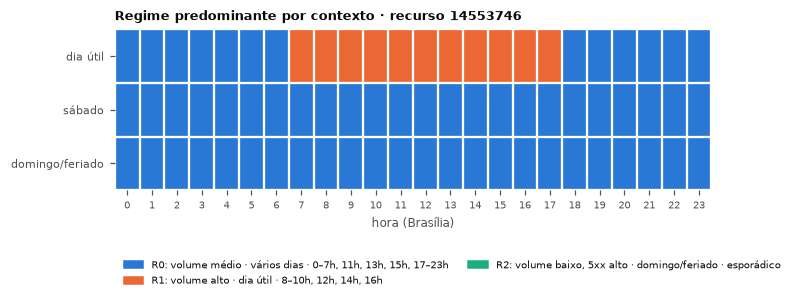

In [10]:
EXEMPLO = 14553746  # 3 regimes estáveis entre quinzenas (ARI 0,80)
d = slots[slots["recurso"] == EXEMPLO].pivot(index="tipo_dia", columns="hora", values="regime")
d = d.loc[["util", "sabado", "domingo_feriado"]]
k = int(regimes.loc[EXEMPLO, "k"])
fig, ax = plt.subplots(figsize=(7.0, 1.9))
ax.imshow(d.to_numpy(), aspect="auto", cmap=ListedColormap(CORES[:k]), vmin=-0.5, vmax=k - 0.5)
ax.set_yticks(range(3))
ax.set_yticklabels([NOMES_DIA[t] for t in d.index])
ax.set_xticks(range(24))
ax.set_xticklabels(range(24), fontsize=6.5)
ax.set_xlabel("hora (Brasília)")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xticks(np.arange(-0.5, 24, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 3, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=1.5)
ax.tick_params(which="minor", length=0)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=CORES[c], label=nomes_todos[EXEMPLO][c]) for c in range(k)],
          loc="upper left", bbox_to_anchor=(0, -0.38), ncol=2, fontsize=6.5)
ax.set_title(f"Regime predominante por contexto · recurso {EXEMPLO}", loc="left")
salvar(fig, "fig_regimes_contexto")
plt.show()

In [11]:
regimes["tipos_dia"] = [3 if r in RECURSOS_3 else 2 for r in regimes.index]
regimes.to_csv(RESULTADOS / "03_regimes_qualidade.csv")
tabela_nomes.to_csv(RESULTADOS / "03_regimes_nomes.csv", index=False)
slots.to_csv(RESULTADOS / "03_regime_por_contexto.csv", index=False)
kw.to_csv(RESULTADOS / "03_kruskal.csv", index=False)
mw.to_csv(RESULTADOS / "03_mann_whitney.csv", index=False)
resumo_testes.to_csv(RESULTADOS / "03_resumo_testes.csv")
salvar_json(dict(frac_kw_sig=float(tot_kw), util_sab_vol_sig=int(util_sab_vol.sum()),
                 sab_dom_vol_sig=int(sab_dom_vol.sum()), n_recursos=len(recursos),
                 recursos_3_tipos=RECURSOS_3,
                 regimes_k_mediana=float(regimes["k"].median()),
                 regimes_k=regimes["k"].to_dict()), "03_resumo.json")